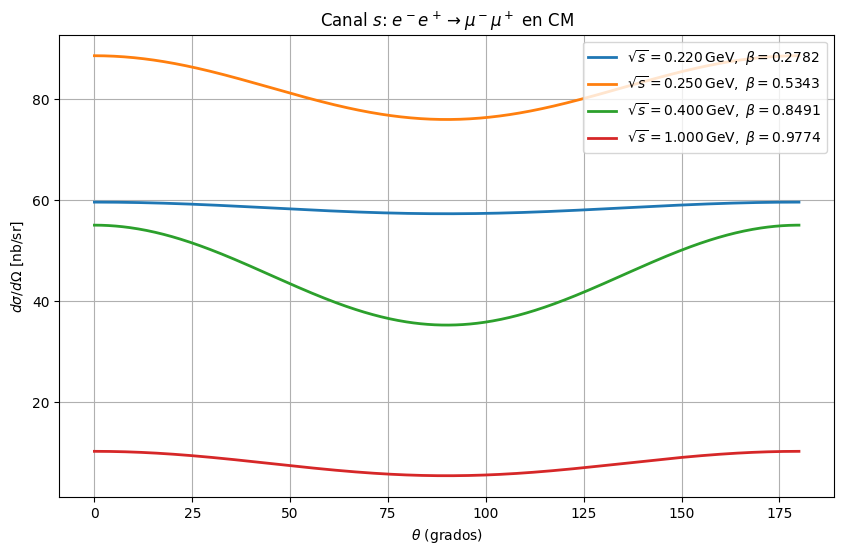

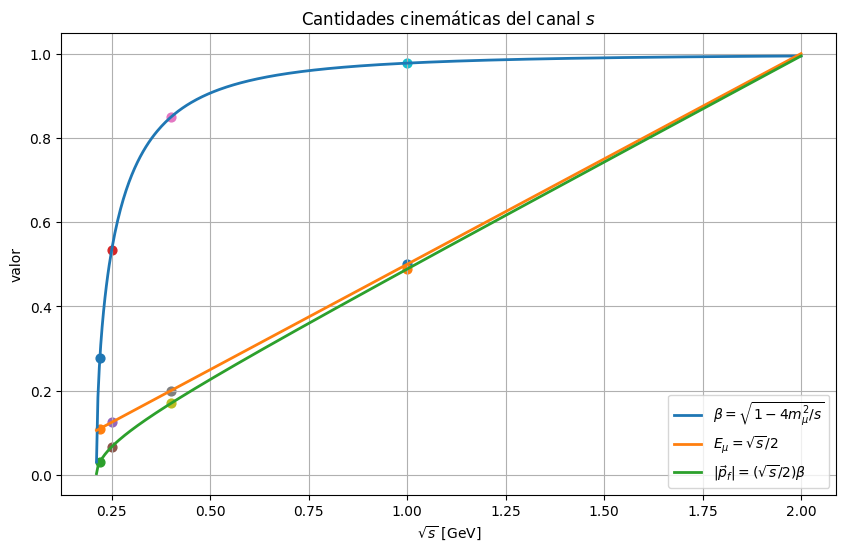

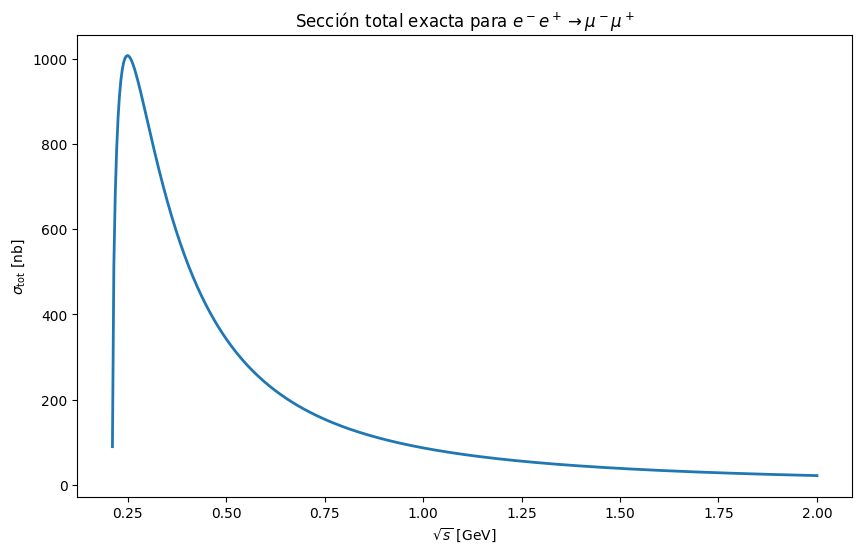

Resumen cinemático para el canal s:

sqrt(s) = 0.220 GeV
  s           = 0.048400 GeV^2
  beta        = 0.278174
  E_mu        = 0.110000 GeV
  |p_f|       = 0.030599 GeV
  sigma_total = 729.466377 nb

sqrt(s) = 0.250 GeV
  s           = 0.062500 GeV^2
  beta        = 0.534344
  E_mu        = 0.125000 GeV
  |p_f|       = 0.066793 GeV
  sigma_total = 1007.833782 nb

sqrt(s) = 0.400 GeV
  s           = 0.160000 GeV^2
  beta        = 0.849063
  E_mu        = 0.200000 GeV
  |p_f|       = 0.169813 GeV
  sigma_total = 525.222788 nb

sqrt(s) = 1.000 GeV
  s           = 1.000000 GeV^2
  beta        = 0.977418
  E_mu        = 0.500000 GeV
  |p_f|       = 0.488709 GeV
  sigma_total = 86.788455 nb



In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
#  e^- e^+ -> mu^- mu^+  (canal s) en el sistema CM
#  Sin tomar el límite ultrarrelativista
#  Unidades: GeV
#  dσ/dΩ en nb/sr
# ============================================================

alpha = 1 / 137.035999084
m_mu = 0.1056583755   # GeV
GEV2_TO_NB = 3.89379e5


def beta_muon(s):
    """
    beta = sqrt(1 - 4 m_mu^2 / s)
    """
    if s <= 4 * m_mu**2:
        return np.nan
    return np.sqrt(1.0 - 4.0 * m_mu**2 / s)


def dsigma_domega_s_channel(theta, s):
    """
    dσ/dΩ para e^-e^+ -> mu^-mu^+ en CM, en GeV^{-2}.
    Fórmula exacta en el canal s (sin límite ultrarrelativista).
    """
    beta = beta_muon(s)
    return (alpha**2 * beta / (4.0 * s)) * (
        1.0 + np.cos(theta)**2 + (1.0 - beta**2) * np.sin(theta)**2
    )


def sigma_total_s_channel(s):
    """
    Sección total exacta:
    sigma = (2 pi alpha^2 / 3s) beta (3 - beta^2)
    """
    beta = beta_muon(s)
    return (2.0 * np.pi * alpha**2 / (3.0 * s)) * beta * (3.0 - beta**2)


# ------------------------------------------------------------
# Valores de sqrt(s) para comparar curvas
# ------------------------------------------------------------
sqrt_s_list = [0.220, 0.250, 0.400, 1.000]  # GeV
theta = np.linspace(0.0, np.pi, 500)
theta_deg = np.degrees(theta)

# ------------------------------------------------------------
# Figura 1: curvas diferenciales para varios sqrt(s)
# ------------------------------------------------------------
plt.figure(figsize=(10, 6))

for sqrt_s in sqrt_s_list:
    s = sqrt_s**2
    beta = beta_muon(s)
    y = dsigma_domega_s_channel(theta, s) * GEV2_TO_NB

    plt.plot(
        theta_deg, y, lw=2,
        label=rf'$\sqrt{{s}}={sqrt_s:.3f}\,\mathrm{{GeV}},\ \beta={beta:.4f}$'
    )

plt.xlabel(r'$\theta$ (grados)')
plt.ylabel(r'$d\sigma/d\Omega\ \mathrm{[nb/sr]}$')
plt.title(r'Canal $s$: $e^-e^+ \to \mu^-\mu^+$ en CM')
plt.grid(True)
plt.legend()
plt.show()

# ------------------------------------------------------------
# Figura 2: beta(s), energía del muón y momento final
# ------------------------------------------------------------
sqrt_s_vals = np.linspace(2.0 * m_mu + 1e-4, 2.0, 500)
s_vals = sqrt_s_vals**2

beta_vals = np.array([beta_muon(s) for s in s_vals])
E_mu_vals = sqrt_s_vals / 2.0
p_f_vals = 0.5 * sqrt_s_vals * beta_vals

plt.figure(figsize=(10, 6))
plt.plot(sqrt_s_vals, beta_vals, lw=2, label=r'$\beta=\sqrt{1-4m_\mu^2/s}$')
plt.plot(sqrt_s_vals, E_mu_vals, lw=2, label=r'$E_\mu=\sqrt{s}/2$')
plt.plot(sqrt_s_vals, p_f_vals, lw=2, label=r'$|\vec p_f|=(\sqrt{s}/2)\beta$')

for sqrt_s in sqrt_s_list:
    s = sqrt_s**2
    beta = beta_muon(s)
    E_mu = sqrt_s / 2.0
    p_f = 0.5 * sqrt_s * beta
    plt.scatter([sqrt_s], [beta], s=40)
    plt.scatter([sqrt_s], [E_mu], s=40)
    plt.scatter([sqrt_s], [p_f], s=40)

plt.xlabel(r'$\sqrt{s}$ [GeV]')
plt.ylabel('valor')
plt.title(r'Cantidades cinemáticas del canal $s$')
plt.grid(True)
plt.legend()
plt.show()

# ------------------------------------------------------------
# Figura 3: sección total exacta como función de sqrt(s)
# ------------------------------------------------------------
sigma_tot_vals = np.array([sigma_total_s_channel(s) for s in s_vals]) * GEV2_TO_NB

plt.figure(figsize=(10, 6))
plt.plot(sqrt_s_vals, sigma_tot_vals, lw=2)
plt.xlabel(r'$\sqrt{s}$ [GeV]')
plt.ylabel(r'$\sigma_{\rm tot}$ [nb]')
plt.title(r'Sección total exacta para $e^-e^+ \to \mu^-\mu^+$')
plt.show()

# ------------------------------------------------------------
# Imprimir algunas cantidades para los sqrt(s) elegidos
# ------------------------------------------------------------
print("Resumen cinemático para el canal s:\n")
for sqrt_s in sqrt_s_list:
    s = sqrt_s**2
    beta = beta_muon(s)
    E_mu = sqrt_s / 2.0
    p_f = 0.5 * sqrt_s * beta
    sigma_tot_nb = sigma_total_s_channel(s) * GEV2_TO_NB

    print(f"sqrt(s) = {sqrt_s:.3f} GeV")
    print(f"  s           = {s:.6f} GeV^2")
    print(f"  beta        = {beta:.6f}")
    print(f"  E_mu        = {E_mu:.6f} GeV")
    print(f"  |p_f|       = {p_f:.6f} GeV")
    print(f"  sigma_total = {sigma_tot_nb:.6f} nb")
    print()